### Q1. Dataset Loading

Load the Iris Dataset using Scikit-learn and display the first 10 records, dataset shape, feature names, and target classes.

In [1]:

import pandas as pd
from sklearn.datasets import load_iris


In [2]:

iris = load_iris()

# Separate features and target
X = iris.data
y = iris.target

# Create a DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:

df.head(10)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
5,5.4,3.9,1.7,0.4,0
6,4.6,3.4,1.4,0.3,0
7,5.0,3.4,1.5,0.2,0
8,4.4,2.9,1.4,0.2,0
9,4.9,3.1,1.5,0.1,0


In [4]:

print("Dataset Shape:", df.shape)


Dataset Shape: (150, 5)


In [5]:

print("Feature Names:")
print(iris.feature_names)


Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [6]:

print("Target Classes:")
print(iris.target_names)


Target Classes:
['setosa' 'versicolor' 'virginica']


### Q2. Exploratory Data Analysis (EDA)

**Perform Exploratory Data Analysis (EDA) by:**

    Checking data types
    Identifying missing values
    Displaying statistical summary
    Displaying the class distribution

In [7]:

print("Data Types:")
print(df.dtypes)


Data Types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
dtype: object


In [8]:

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [9]:

print("Statistical Summary:")
df.describe()


Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [10]:

print("Class Distribution:")
print(df["target"].value_counts().sort_index())

print("\nClass Names:")
print(iris.target_names)


Class Distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64

Class Names:
['setosa' 'versicolor' 'virginica']


### Q3. Data Preprocessing

**Prepare the dataset by:**

    Separating features (X) and target (y)
    Splitting the data into 80% training and 20% testing sets using random_state=42

In [11]:

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())


Features (X):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target (y):
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64


In [12]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)


Training Features Shape: (120, 4)
Testing Features Shape: (30, 4)
Training Target Shape: (120,)
Testing Target Shape: (30,)


### Q4. Model Training

Train a Logistic Regression classifier using the training dataset and make predictions on the testing dataset.

In [13]:

from sklearn.linear_model import LogisticRegression



In [14]:

# Create the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [15]:

# Predict the test dataset
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.to_numpy())

print("\nPredicted Values:")
print(y_pred)


Actual Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [16]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy Percentage:", accuracy * 100, "%")


Model Accuracy: 1.0
Model Accuracy Percentage: 100.0 %


### Q5. Confusion Matrix

**Generate the Confusion Matrix and explain the meaning of:**

    True Positive (TP)
    True Negative (TN)
    False Positive (FP)
    False Negative (FN)

In [17]:

from sklearn.metrics import confusion_matrix


In [18]:

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


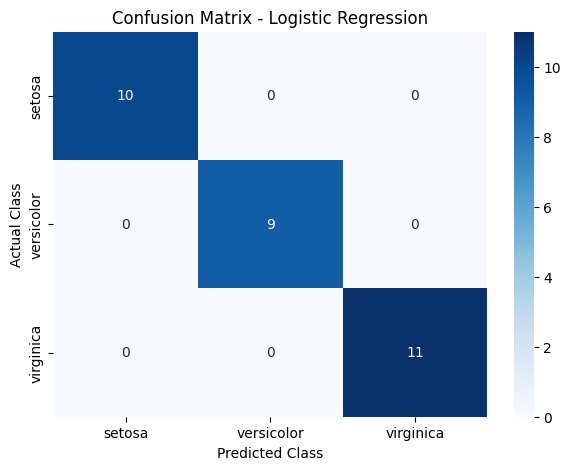

In [19]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


In [20]:

import numpy as np

for i, class_name in enumerate(iris.target_names):
    TP = cm[i, i]
    FP = cm[:, i].sum() - TP
    FN = cm[i, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)

    print(f"\nClass: {class_name}")
    print("True Positive (TP):", TP)
    print("True Negative (TN):", TN)
    print("False Positive (FP):", FP)
    print("False Negative (FN):", FN)



Class: setosa
True Positive (TP): 10
True Negative (TN): 20
False Positive (FP): 0
False Negative (FN): 0

Class: versicolor
True Positive (TP): 9
True Negative (TN): 21
False Positive (FP): 0
False Negative (FN): 0

Class: virginica
True Positive (TP): 11
True Negative (TN): 19
False Positive (FP): 0
False Negative (FN): 0


### Q6. Classification Metrics

**Calculate and interpret the following metrics:**

    Accuracy
    Precision
    Recall
    F1-Score

In [21]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [22]:

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

# Display results
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


### Q7. Classification Report

Generate the Classification Report and explain the significance of Precision, Recall, F1-Score, and Support for each class.

In [23]:

from sklearn.metrics import classification_report


In [24]:

report = classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
)

print("Classification Report:")
print(report)


Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [25]:

report_dict = classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()

report_df


,precision,recall,f1-score,support
setosa,1.0,1.0,1.0,10.0
versicolor,1.0,1.0,1.0,9.0
virginica,1.0,1.0,1.0,11.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,30.0
weighted avg,1.0,1.0,1.0,30.0


### Q8. Visualization

**Create the following visualizations:**

    Confusion Matrix Heatmap
    Bar Chart comparing Accuracy, Precision, Recall, and F1-Score
    Write your observations.

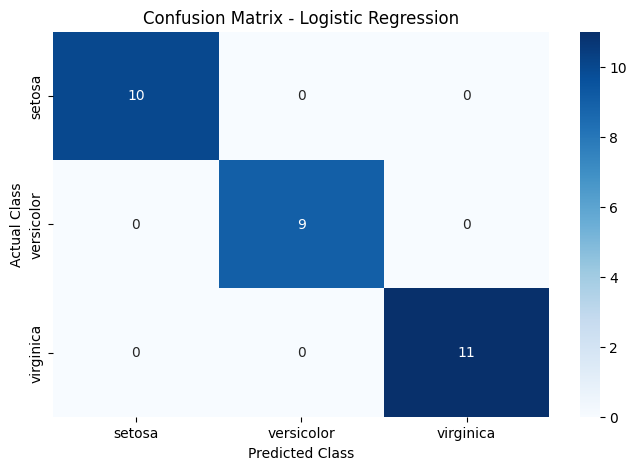

In [26]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()


**Observations:**

1. Higher diagonal values indicate more correct predictions.
2. Values outside the diagonal indicate classification errors.
3. A matrix with zero off-diagonal values indicates that all test records were classified correctly.

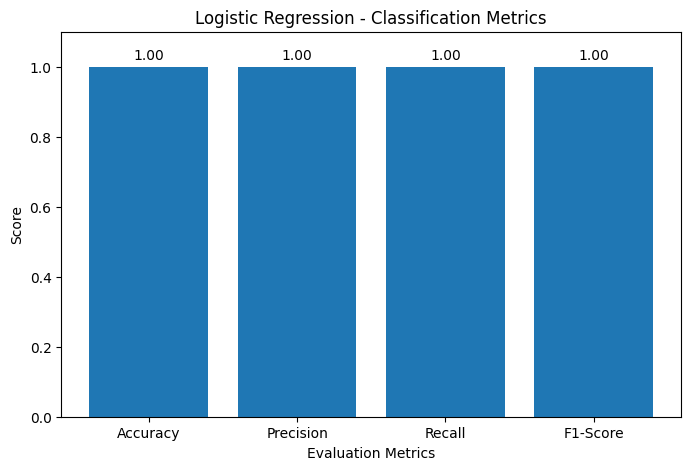

In [27]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, average="weighted"
    ),
    "Recall": recall_score(
        y_test, y_pred, average="weighted"
    ),
    "F1-Score": f1_score(
        y_test, y_pred, average="weighted"
    )
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.title("Logistic Regression - Classification Metrics")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha="center")

plt.show()


**Observation:**

- The bar chart compares the four evaluation metrics.
- Scores closer to 1.0 indicate stronger performance.
- The displayed scores are calculated from your actual predictions.

### Q9. Model Comparison

**Train another classification model (e.g., Decision Tree or K-Nearest Neighbors) on the same dataset and compare its performance metrics with Logistic Regression.**

In [28]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score


In [29]:

# Logistic Regression model
lr_model = LogisticRegression(max_iter=200)
lr_model.fit(X_train, y_train)

# Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [30]:

# Predictions from both models
lr_pred = lr_model.predict(X_test)
dt_pred = dt_model.predict(X_test)

print("Logistic Regression Predictions:")
print(lr_pred)

print("\nDecision Tree Predictions:")
print(dt_pred)


Logistic Regression Predictions:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Decision Tree Predictions:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [31]:

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Logistic Regression Accuracy:",
      round(lr_accuracy, 4))

print("Decision Tree Accuracy:",
      round(dt_accuracy, 4))


Logistic Regression Accuracy: 1.0
Decision Tree Accuracy: 1.0


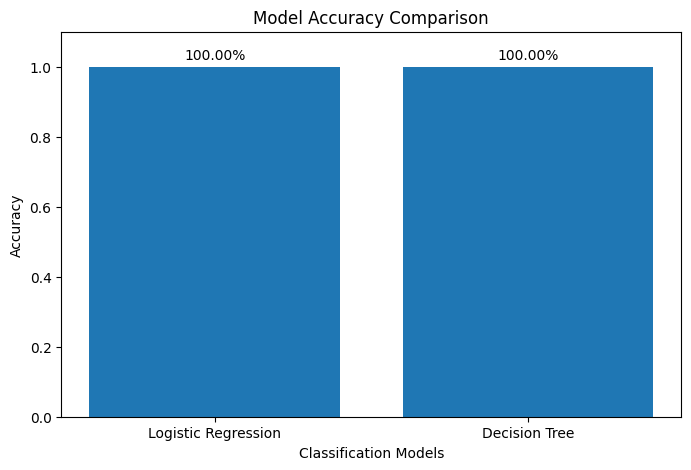

In [32]:

models = ["Logistic Regression", "Decision Tree"]
accuracies = [lr_accuracy, dt_accuracy]

plt.figure(figsize=(8, 5))

plt.bar(models, accuracies)

plt.title("Model Accuracy Comparison")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)

for i, value in enumerate(accuracies):
    plt.text(i, value + 0.02, f"{value:.2%}", ha="center")

plt.show()


In [33]:

comparison_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [lr_accuracy, dt_accuracy]
})

comparison_df


,Model,Accuracy
0,Logistic Regression,1.0
1,Decision Tree,1.0


### Q10. Final Project Report — Iris Dataset Classification Using Logistic Regression
1. Project Overview

    The objective of this project is to build a Machine Learning classification model that predicts the species of an Iris flower based on its sepal and petal measurements.
    The Iris dataset contains 150 records, four numerical input features, and three target classes: Setosa, Versicolor, and Virginica.
2. Overall Model Performance
    The Logistic Regression model was trained using 80% of the dataset and evaluated using the remaining 20%.
    The following metrics were used to evaluate the model:
    - Accuracy: Measures the percentage of correct predictions.
    - Precision: Measures the correctness of positive class predictions.
    - Recall: Measures how many actual class records were correctly identified.
    - F1-Score: Balances precision and recall.